# La crypto est-elle devenue un actif comme les autres ?

Ce notebook répond à la question en trois temps :

1. **Le risque** : la crypto est-elle toujours aussi volatile ?
2. **Le lien** : évolue-t-elle désormais avec la bourse ?
3. **Les crises** : protège-t-elle quand les marchés chutent ?

Les données viennent des tables construites par dbt (voir `transform/`).
Toutes les comparaisons entre actifs utilisent le **calendrier commun des jours de bourse US**
(`marts.fct_aligned_returns`) : le README explique pourquoi ce choix change les résultats.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd

from src.analysis import charts, data
from src.analysis import metrics as m

pd.set_option("display.precision", 2)

# Indices et crypto étudiés ici. Les ETF (SPY, GLD, BIL) servent aux simulations du notebook 02.
ANALYSED = ["BTC", "ETH", "SOL", "SPX", "NDX", "CAC", "TLT", "GOLD"]

assets = data.load_assets()
native = data.load_native()[ANALYSED]          # chaque actif sur son propre calendrier
aligned = data.load_aligned()[ANALYSED]        # tous les actifs sur les jours de bourse US
prices = data.load_aligned("price")[ANALYSED]

print(f"Période : {aligned.index.min():%d/%m/%Y} → {aligned.index.max():%d/%m/%Y}, "
      f"{len(aligned)} jours de bourse, {aligned.shape[1]} actifs")

Période : 03/01/2018 → 26/10/2026, 2215 jours de bourse, 8 actifs


## 0. Vue d'ensemble

Pour chaque actif, sur son propre calendrier (365 jours par an pour la crypto, 252 pour le reste) :

In [2]:
summary = m.summary_table(native, assets).sort_values("volatilite_annuelle", ascending=False)
summary.style.format(
    {
        "rendement_annuel": "{:+.1%}",
        "volatilite_annuelle": "{:.0%}",
        "sharpe": "{:.2f}",
        "pire_baisse": "{:.0%}",
        "pire_jour": "{:.0%}",
    }
)

,classe,depuis,rendement_annuel,volatilite_annuelle,sharpe,pire_baisse,pire_jour
symbol,,,,,,,
SOL,crypto,2020-08-12,+73.5%,113%,1.05,-96%,-42%
ETH,crypto,2018-01-02,+13.6%,85%,0.58,-94%,-45%
BTC,crypto,2018-01-02,+22.5%,65%,0.64,-81%,-40%
NDX,action,2018-01-03,+16.2%,23%,0.76,-36%,-12%
SPX,action,2018-01-03,+12.6%,19%,0.72,-34%,-12%
CAC,action,2018-01-03,+4.5%,18%,0.33,-39%,-12%
GOLD,matiere_premiere,2018-01-03,+13.6%,18%,0.81,-25%,-11%
TLT,obligation,2018-01-03,-2.0%,15%,-0.05,-48%,-7%


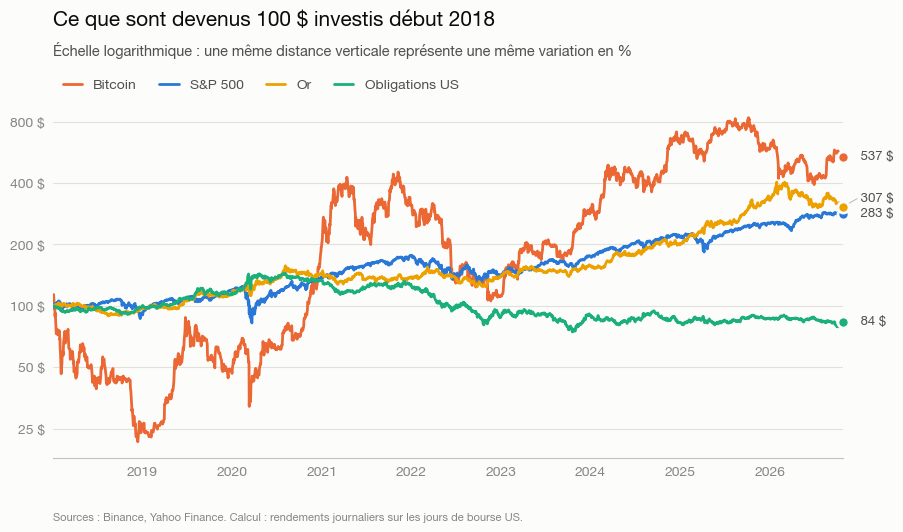

In [3]:
fig = charts.growth_of_100(prices, ["BTC", "SPX", "GOLD", "TLT"])
_ = charts.save(fig, "01_croissance_100")

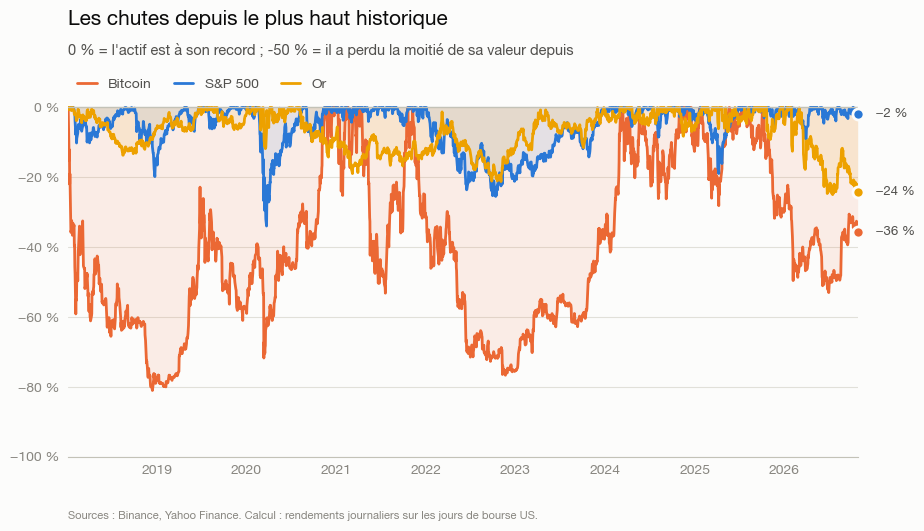

In [4]:
fig = charts.drawdowns(prices, ["BTC", "SPX", "GOLD"])
_ = charts.save(fig, "02_drawdowns")

**À retenir**

- Parmi les actifs suivis depuis 2018, le Bitcoin a le meilleur rendement (+22 % par an), mais c'est
  aussi celui qui a le plus fait souffrir : jusqu'à **-81 %** depuis son record. Ethereum et Solana
  vont encore plus loin dans les deux sens.
- Rapporté au risque pris (ratio de Sharpe), le Bitcoin (0,64) fait **moins bien** que le S&P 500
  (0,72), le Nasdaq (0,76) ou l'or (0,81) : son rendement supérieur rémunère tout juste sa volatilité.
- Les obligations longues US (TLT) ont perdu de l'argent sur la période, à cause de la forte hausse
  des taux de 2022.

## 1. Le risque : la crypto est-elle toujours aussi volatile ?

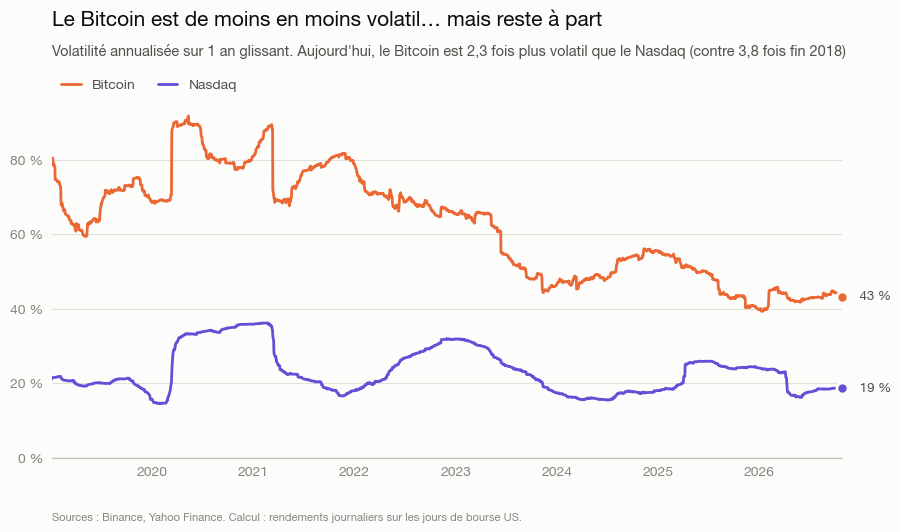

In [5]:
vols = pd.DataFrame(
    {s: m.rolling_volatility(aligned, s, window=252) for s in ["BTC", "NDX"]}
)
ratio = vols["BTC"] / vols["NDX"]
fig = charts.rolling_volatility(vols, ratio)
_ = charts.save(fig, "03_volatilite")

In [6]:
ratio.groupby(ratio.index.year).mean().rename("BTC / Nasdaq (moyenne annuelle)").to_frame().T

date,2018,2019,2020,2021,2022,2023,2024,2025,2026
BTC / Nasdaq (moyenne annuelle),NaN,3.44,2.86,3.54,2.81,2.22,3.02,2.1,2.23


**À retenir**

- La volatilité du Bitcoin a été **divisée par deux** : environ 80 % par an en 2020-2021,
  autour de 40 % aujourd'hui.
- L'écart avec la bourse s'est réduit, sans disparaître : le Bitcoin était en moyenne **3,5 fois**
  plus volatil que le Nasdaq en 2019 et 2021, il l'est encore **un peu plus de 2 fois** en 2025-2026.
  Or le Nasdaq est déjà l'indice le plus volatil de la bourse US. Sur ce critère, le Bitcoin
  n'est pas encore un actif « comme les autres ».

## 2. Le lien : la crypto évolue-t-elle avec la bourse ?

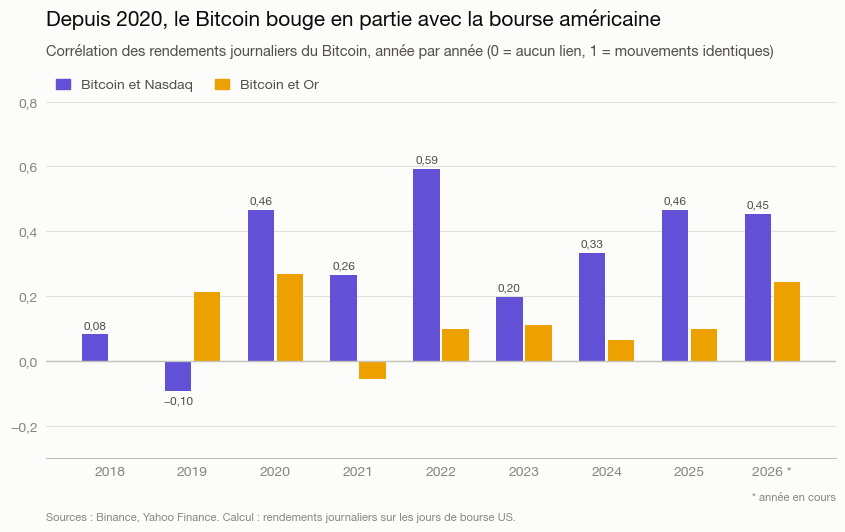

In [7]:
yearly = pd.DataFrame(
    {s: m.yearly_correlation(aligned, "BTC", s) for s in ["NDX", "GOLD"]}
)
fig = charts.yearly_correlation(yearly, highlight="NDX")
_ = charts.save(fig, "04_correlation_annuelle")

In [8]:
# Krachs du S&P 500 détectés automatiquement (baisse de plus de 10 % depuis un sommet)
crises = m.drawdown_episodes(prices["SPX"].dropna(), threshold=-0.10)
crisis_names = {
    "2018-01": "Fév. 2018",
    "2018-09": "Fin 2018",
    "2020-02": "COVID",
    "2022-01": "Inflation 2022",
    "2025-02": "Droits de douane",
}
crises["nom"] = crises["sommet"].dt.strftime("%Y-%m").map(crisis_names)
crises

,sommet,point_bas,retour_au_sommet,baisse,jours_de_baisse,nom
0,2018-01-26,2018-02-08,2018-08-24,-0.10,13,Fév. 2018
1,2018-09-20,2018-12-24,2019-04-23,-0.20,95,Fin 2018
2,2020-02-19,2020-03-23,2020-08-18,-0.34,33,COVID
3,2022-01-03,2022-10-12,2024-01-19,-0.25,282,Inflation 2022
4,2025-02-19,2025-04-08,2025-06-27,-0.19,48,Droits de douane


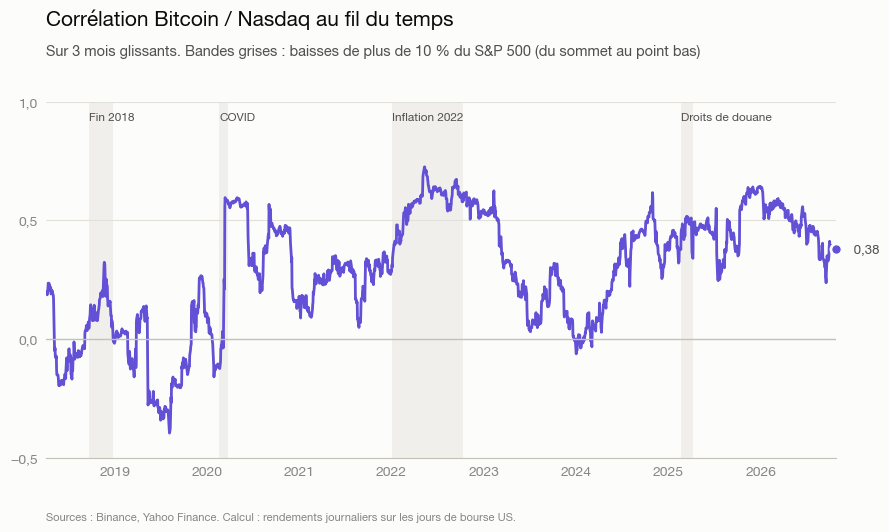

In [9]:
corr_63 = m.rolling_correlation(aligned, "BTC", "NDX", window=63)
fig = charts.rolling_correlation(corr_63, ("BTC", "NDX"), crises, window_label="3 mois")
_ = charts.save(fig, "05_correlation_glissante")

In [10]:
periods = {
    "2018-2019": ("2018", "2019"),
    "2020-2022": ("2020", "2022"),
    "2023-aujourd'hui": ("2023", "2026"),
}
by_period = m.correlation_by_period(aligned, periods)
pd.DataFrame(
    {name: c.loc[["BTC", "ETH", "SOL"], "NDX"] for name, c in by_period.items()}
).rename_axis("corrélation avec le Nasdaq")

,2018-2019,2020-2022,2023-aujourd'hui
corrélation avec le Nasdaq,,,
BTC,0.02,0.44,0.35
ETH,0.07,0.44,0.40
SOL,NaN,0.35,0.32


**À retenir**

- **Avant 2020, aucun lien** : la corrélation du Bitcoin avec le Nasdaq était proche de zéro.
  La crypto vivait dans son propre monde.
- **Depuis 2020, un lien durable** : la corrélation oscille entre 0,2 et 0,6 selon les années,
  avec un pic à 0,72 en mai 2022, en pleine hausse des taux. Le Bitcoin réagit désormais aux
  mêmes nouvelles que la bourse : taux d'intérêt, inflation, appétit pour le risque.
- **La bourse américaine, pas spécialement la tech** : sur 2020-2026, la corrélation est presque la même
  avec le Nasdaq (0,41) qu'avec le S&P 500 (0,39), deux indices qui bougent eux-mêmes ensemble (0,95).
  Elle est plus faible avec le CAC 40 (0,26).
- **Aucun lien avec l'or** (autour de 0,1) : l'image d'« or numérique » ne se retrouve pas dans les données.
- Ethereum et Solana suivent le même schéma que le Bitcoin.

## 3. Les crises : la crypto protège-t-elle ?

,baisse,tous,hausse
BTC,0.39,0.32,0.22
ETH,0.40,0.34,0.25
GOLD,0.11,0.10,0.12
TLT,-0.15,-0.09,-0.12


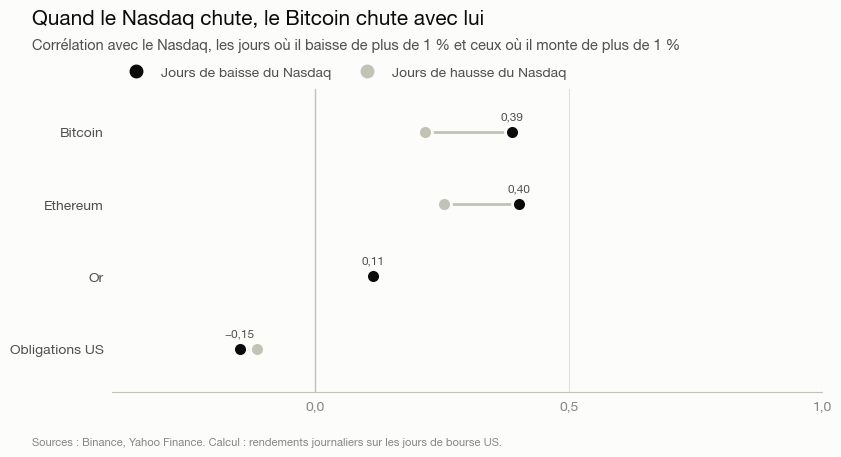

In [11]:
conditional = pd.DataFrame(
    {
        s: m.conditional_correlation(aligned, s, "NDX").values
        for s in ["BTC", "ETH", "GOLD", "TLT"]
    },
    index=["baisse", "tous", "hausse"],
).T
fig = charts.conditional_correlation(conditional, reference="NDX")
_ = charts.save(fig, "06_correlation_conditionnelle")
conditional

symbol,SPX,BTC,TLT,GOLD
Fév. 2018,-10%,-30%,-4%,-3%
Fin 2018,-20%,-38%,+5%,+5%
COVID,-34%,-33%,+14%,-3%
Inflation 2022,-25%,-59%,-29%,-7%
Droits de douane,-19%,-21%,+1%,+2%


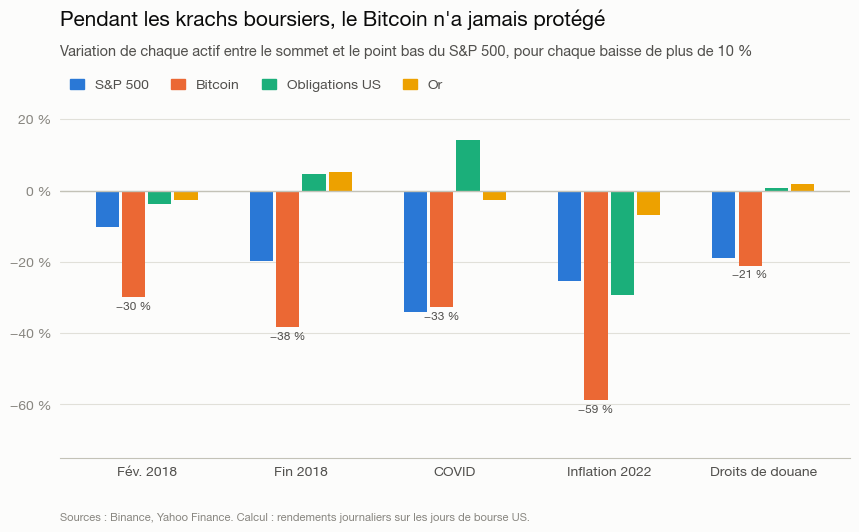

In [12]:
crisis_perf = pd.DataFrame(
    {
        c["nom"]: m.performance_during(prices[["SPX", "BTC", "TLT", "GOLD"]], c["sommet"], c["point_bas"])
        for _, c in crises.iterrows()
    }
).T
fig = charts.crisis_performance(crisis_perf, highlight="BTC")
_ = charts.save(fig, "07_krachs")
crisis_perf.style.format("{:+.0%}")

Et dans l'autre sens : pendant les grands krachs **propres à la crypto**, que faisait la bourse ?

In [13]:
btc_crashes = m.drawdown_episodes(prices["BTC"].dropna(), threshold=-0.30)
btc_crashes["S&P 500 sur la même période"] = [
    m.performance_during(prices["SPX"], c["sommet"], c["point_bas"]) for _, c in btc_crashes.iterrows()
]
btc_crashes.style.format(
    {"baisse": "{:.0%}", "S&P 500 sur la même période": "{:+.0%}"}, na_rep="pas encore"
)

,sommet,point_bas,retour_au_sommet,baisse,jours_de_baisse,S&P 500 sur la même période
0,2018-01-05 00:00:00,2018-12-14 00:00:00,2020-11-17 00:00:00,-81%,343,-5%
1,2021-04-13 00:00:00,2021-07-20 00:00:00,2021-10-19 00:00:00,-53%,98,+4%
2,2021-11-08 00:00:00,2022-11-21 00:00:00,2024-03-04 00:00:00,-77%,378,-16%
3,2025-10-06 00:00:00,2026-06-30 00:00:00,pas encore,-53%,267,+11%


**À retenir**

- Le lien est **asymétrique** : la corrélation du Bitcoin avec le Nasdaq monte à 0,39 les jours
  de forte baisse, contre 0,22 les jours de forte hausse. Il chute avec la bourse, sans en profiter
  autant quand elle remonte. C'est le contraire d'une protection.
- Dans **chacun des 5 krachs** du S&P 500 depuis 2018, le Bitcoin a baissé : à peu près autant
  que lui pendant le COVID (-33 % contre -34 %), bien plus dans les quatre autres
  (-59 % contre -25 % en 2022). L'or a très peu bougé (entre -7 % et +5 %). Les obligations ont
  nettement protégé pendant le COVID (+14 %), mais ont chuté avec les actions en 2022 (-29 %),
  quand l'inflation a fait monter les taux.
- À l'inverse, la crypto a aussi **ses propres krachs**, sans la bourse : au printemps 2021,
  le Bitcoin perd 53 % pendant que le S&P 500 gagne 4 % ; d'octobre 2025 à juin 2026, il perd encore
  53 % pendant que le S&P 500 gagne 11 %. La crypto ajoute donc ses crises à celles de la bourse.

## Conclusion

**La crypto est devenue un actif lié aux marchés, mais pas un actif comme les autres.**

| Critère | Verdict |
|---|---|
| Lien avec la bourse | **Oui depuis 2020** : elle bouge en partie avec la bourse américaine (corrélation autour de 0,4, contre 0 avant) |
| Volatilité | **Encore à part** : divisée par deux, mais toujours plus de 2 fois celle du Nasdaq |
| Protection en crise | **Non** : elle chute avec la bourse, souvent plus fort, et a en plus ses propres krachs |
| « Or numérique » | **Non** : aucun lien avec l'or dans les données |

Concrètement, pour un investisseur, la crypto se comporte comme **un actif risqué de plus**, lié à la bourse américaine
mais bien plus volatil, pas comme une valeur refuge. La question suivante est donc : ajouter un peu de crypto à un
portefeuille classique améliore-t-il quand même son couple rendement / risque ?
Ce sera l'objet de l'étape 4.

*Limites : période courte (2018-2026) au regard de l'histoire des marchés, taux sans risque
fixé à 0 dans le ratio de Sharpe, heures de clôture différentes entre Binance et Wall Street.*